In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score
)

In [2]:
df = pd.read_csv(r"C:\Users\pruth\Downloads\archive (1)\heart_disease_uci.csv")

print(df.head(10))
print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

   id  age     sex    dataset               cp  trestbps   chol    fbs  \
0   1   63    Male  Cleveland   typical angina     145.0  233.0   True   
1   2   67    Male  Cleveland     asymptomatic     160.0  286.0  False   
2   3   67    Male  Cleveland     asymptomatic     120.0  229.0  False   
3   4   37    Male  Cleveland      non-anginal     130.0  250.0  False   
4   5   41  Female  Cleveland  atypical angina     130.0  204.0  False   
5   6   56    Male  Cleveland  atypical angina     120.0  236.0  False   
6   7   62  Female  Cleveland     asymptomatic     140.0  268.0  False   
7   8   57  Female  Cleveland     asymptomatic     120.0  354.0  False   
8   9   63    Male  Cleveland     asymptomatic     130.0  254.0  False   
9  10   53    Male  Cleveland     asymptomatic     140.0  203.0   True   

          restecg  thalch  exang  oldpeak        slope   ca  \
0  lv hypertrophy   150.0  False      2.3  downsloping  0.0   
1  lv hypertrophy   108.0   True      1.5         flat  3.0

In [3]:
df.columns = df.columns.str.strip().str.lower()

if "target" in df.columns:
    target_col = "target"
elif "num" in df.columns:
    target_col = "num"
else:
    raise ValueError("Target column not found. Check df.columns.")

df = df.drop_duplicates().copy()

# Convert the target into binary labels:
# 0 = no disease, 1 = disease present
y = (pd.to_numeric(df[target_col], errors="coerce") > 0).astype(int)

X = df.drop(columns=[target_col])
X = X.apply(pd.to_numeric, errors="coerce")

# Remove rows with invalid target values
valid = pd.to_numeric(df[target_col], errors="coerce").notna()
X = X.loc[valid]
y = y.loc[valid]

print("Missing values in features:")
print(X.isnull().sum())

print("\nTarget distribution:")
print(y.value_counts())

Missing values in features:
id            0
age           0
sex         920
dataset     920
cp          920
trestbps     59
chol         30
fbs          90
restecg     920
thalch       55
exang        55
oldpeak      62
slope       920
ca          611
thal        920
dtype: int64

Target distribution:
num
1    509
0    411
Name: count, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=4, random_state=42
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully


C:\Users\pruth\anaconda3\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['sex' 'dataset' 'cp' 'restecg' 'slope' 'thal']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\pruth\anaconda3\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['sex' 'dataset' 'cp' 'restecg' 'slope' 'thal']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [6]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)
print(results_df.round(3))

                 Model  Accuracy  Precision  Recall
0  Logistic Regression     0.815      0.815   0.863
1        Decision Tree     0.842      0.829   0.902


C:\Users\pruth\anaconda3\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['sex' 'dataset' 'cp' 'restecg' 'slope' 'thal']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\pruth\anaconda3\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['sex' 'dataset' 'cp' 'restecg' 'slope' 'thal']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


C:\Users\pruth\anaconda3\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['sex' 'dataset' 'cp' 'restecg' 'slope' 'thal']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


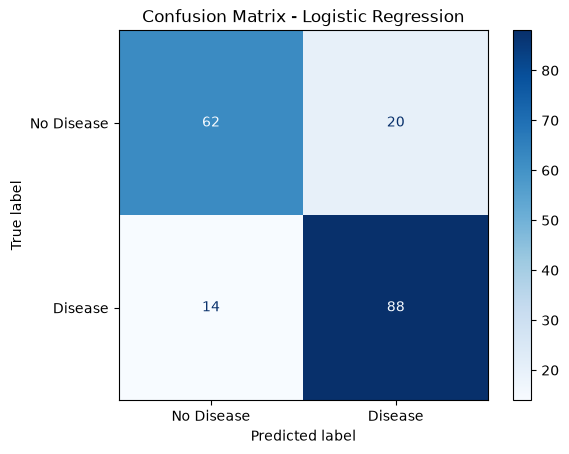

C:\Users\pruth\anaconda3\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['sex' 'dataset' 'cp' 'restecg' 'slope' 'thal']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


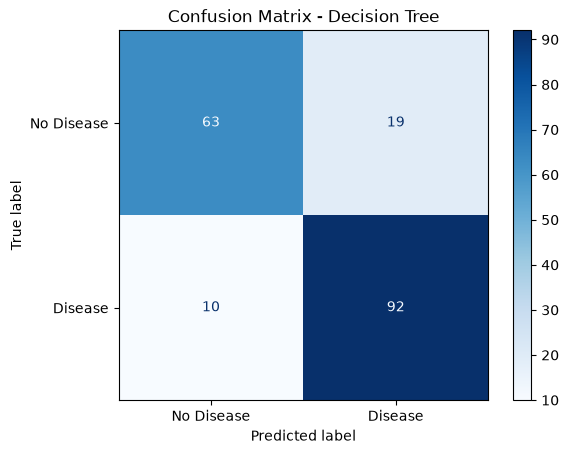

In [7]:
for name, model in models.items():
    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["No Disease", "Disease"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.show()

C:\Users\pruth\anaconda3\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['sex' 'dataset' 'cp' 'restecg' 'slope' 'thal']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\pruth\anaconda3\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['sex' 'dataset' 'cp' 'restecg' 'slope' 'thal']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


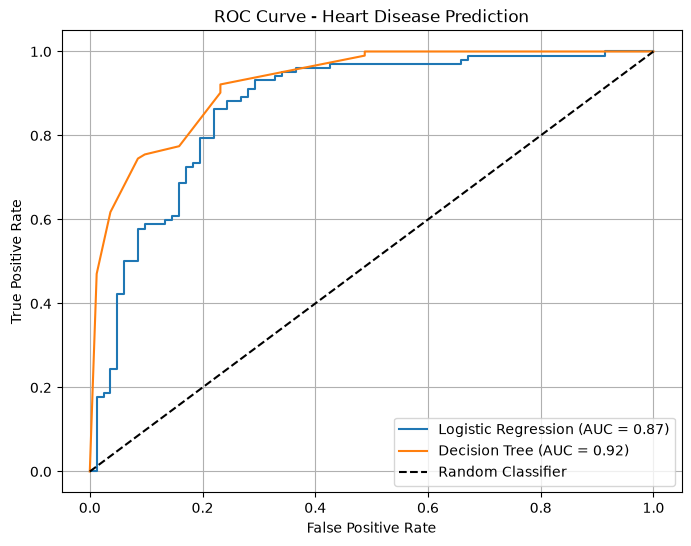

In [8]:
plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.2f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Heart Disease Prediction")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
for name, model in models.items():
    print("\n", name)
    print(classification_report(
        y_test,
        model.predict(X_test),
        target_names=["No Disease", "Disease"],
        zero_division=0
    ))


 Logistic Regression
              precision    recall  f1-score   support

  No Disease       0.82      0.76      0.78        82
     Disease       0.81      0.86      0.84       102

    accuracy                           0.82       184
   macro avg       0.82      0.81      0.81       184
weighted avg       0.82      0.82      0.81       184


 Decision Tree
              precision    recall  f1-score   support

  No Disease       0.86      0.77      0.81        82
     Disease       0.83      0.90      0.86       102

    accuracy                           0.84       184
   macro avg       0.85      0.84      0.84       184
weighted avg       0.84      0.84      0.84       184



C:\Users\pruth\anaconda3\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['sex' 'dataset' 'cp' 'restecg' 'slope' 'thal']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\pruth\anaconda3\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['sex' 'dataset' 'cp' 'restecg' 'slope' 'thal']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
